# 02 – Statistical tests: are the patterns real or just noise?
The SQL step showed three patterns. Here we check them with statistical tests (BSc Statistics in practice):
1. **Calibration / favourite-longshot bias**: outsiders win less often than their odds suggest, favourites more often.
2. **Home advantage**: much smaller in 2020/21 (empty stadiums).
3. **Which bookmaker predicts better**: Bet365 vs Pinnacle (Brier score).

Rule we use: p-value < 0.05 → the difference is unlikely to be random chance (statistically significant).

In [1]:
import os
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

BASE = r"C:\Projects\greek-betting-markets"
DB = os.path.join(BASE, "data-clean", "greek_betting.db")
IMG = os.path.join(BASE, "images")
os.makedirs(IMG, exist_ok=True)

with sqlite3.connect(DB) as con:
    m = pd.read_sql("SELECT * FROM matches", con)
print(len(m), "matches")

2388 matches


## 1. Calibration test per probability band
Every match gives 3 outcomes (Home, Draw, Away), each with a fair Bet365 probability.
For each band we compare **expected wins** (sum of probabilities) with **actual wins**.

Test: **binomial test**. If the odds were accurate, actual wins ~ Binomial(n, average probability).

In [2]:
rows = []
for o, flag in [("H", "HomeWin"), ("D", "Draw"), ("A", "AwayWin")]:
    part = m[[f"B365_Prob{o}", flag, f"B365{o}"]].dropna()
    part.columns = ["prob", "happened", "odds"]
    part["outcome"] = {"H": "Home", "D": "Draw", "A": "Away"}[o]
    rows.append(part)
outcomes = pd.concat(rows, ignore_index=True)
print(len(outcomes), "outcomes")

bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]
labels = ["0-10%", "10-20%", "20-30%", "30-40%", "40-50%", "50-60%", "60-70%", "70-80%", "80-100%"]
outcomes["band"] = pd.cut(outcomes["prob"], bins=bins, labels=labels, right=False)

def test_band(g):
    n = len(g)
    k = int(g["happened"].sum())
    p = g["prob"].mean()
    return pd.Series({
        "outcomes": n,
        "predicted_pct": 100 * p,
        "actual_pct": 100 * k / n,
        "difference_pp": 100 * (k / n - p),
        "p_value": stats.binomtest(k, n, p).pvalue,
    })

calib = outcomes.groupby("band", observed=True).apply(test_band)
calib["significant"] = np.where(calib["p_value"] < 0.05, "yes", "no")
calib.round({"predicted_pct": 1, "actual_pct": 1, "difference_pp": 1, "p_value": 4})

7050 outcomes


C:\Users\zozo\AppData\Local\Temp\ipykernel_4124\201090533.py:26: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  calib = outcomes.groupby("band", observed=True).apply(test_band)


,outcomes,predicted_pct,actual_pct,difference_pp,p_value,significant
band,,,,,,
0-10%,440.0,7.1,3.9,-3.3,0.0053,yes
10-20%,1124.0,15.2,13.5,-1.7,0.1242,no
20-30%,2225.0,26.1,27.7,1.6,0.0866,no
30-40%,1336.0,33.5,33.4,-0.2,0.9078,no
40-50%,688.0,44.9,39.1,-5.8,0.0024,yes
50-60%,444.0,54.7,54.5,-0.2,0.9620,no
60-70%,375.0,64.9,68.5,3.7,0.1442,no
70-80%,279.0,74.9,80.6,5.8,0.0270,yes
80-100%,139.0,82.8,89.9,7.1,0.0242,yes


### Calibration chart
Points on the dashed line = perfectly accurate odds. Points **below** the line on the left = outsiders win less than the odds say. Points **above** the line on the right = favourites win more.

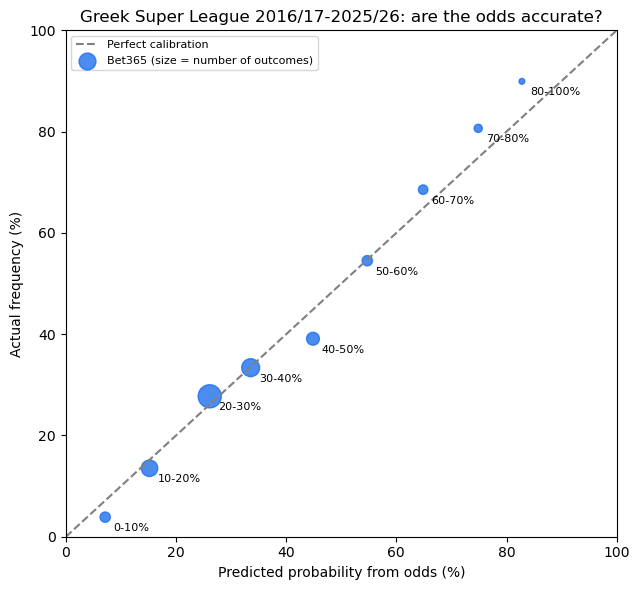

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 100], [0, 100], linestyle="--", color="grey", label="Perfect calibration")
ax.scatter(calib["predicted_pct"], calib["actual_pct"], s=calib["outcomes"] / 8, color="#1f6feb", alpha=0.8,
           label="Bet365 (size = number of outcomes)")
for band, r in calib.iterrows():
    ax.annotate(band, (r["predicted_pct"], r["actual_pct"]), textcoords="offset points", xytext=(6, -10), fontsize=8)
ax.set_xlabel("Predicted probability from odds (%)")
ax.set_ylabel("Actual frequency (%)")
ax.set_title("Greek Super League 2016/17-2025/26: are the odds accurate?")
ax.legend(loc="upper left", fontsize=8)
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
plt.tight_layout()
plt.savefig(os.path.join(IMG, "calibration.png"), dpi=150)
plt.show()

## 2. Favourite vs longshot: is the difference in return significant?
We compare outcomes priced at **odds 10.00+** (longshots) with **odds below 1.50** (strong favourites).
For each group: actual win rate vs fair probability, with a binomial test.

In [4]:
groups = {
    "Strong favourites (odds < 1.50)": outcomes[outcomes["odds"] < 1.5],
    "Longshots (odds >= 10.00)": outcomes[outcomes["odds"] >= 10],
}
res = []
for name, g in groups.items():
    if g.empty:
        continue
    n, k, p = len(g), int(g["happened"].sum()), g["prob"].mean()
    res.append({"group": name, "outcomes": n, "fair_prob_pct": round(100 * p, 1),
                "actual_pct": round(100 * k / n, 1),
                "p_value": round(stats.binomtest(k, n, p).pvalue, 4)})
pd.DataFrame(res)

,group,outcomes,fair_prob_pct,actual_pct,p_value
0,Strong favourites (odds < 1.50),655,73.6,78.3,0.0060
1,Longshots (odds >= 10.00),410,6.9,3.4,0.0033


## 3. Home advantage: was 2020/21 (empty stadiums) different?
Test: **chi-square test of independence** on a 2×3 table: period (2020/21 vs all other seasons) × result (H / D / A).

In [5]:
m["Period"] = np.where(m["Season"] == "2020/21", "2020/21 (empty stadiums)", "Other seasons")
table = pd.crosstab(m["Period"], m["FTR"])[["H", "D", "A"]]
chi2, p, dof, _ = stats.chi2_contingency(table)
print(table)
print()
print((pd.crosstab(m["Period"], m["FTR"], normalize="index")[["H", "D", "A"]] * 100).round(1))
print(f"\nchi-square = {chi2:.2f}, degrees of freedom = {dof}, p-value = {p:.4f}")

FTR                         H    D    A
Period                                 
2020/21 (empty stadiums)   91   70   79
Other seasons             945  576  627

FTR                          H     D     A
Period                                    
2020/21 (empty stadiums)  37.9  29.2  32.9
Other seasons             44.0  26.8  29.2

chi-square = 3.29, degrees of freedom = 2, p-value = 0.1927


And the long-term trend: does the home-win share fall over the 10 seasons?
Test: **linear regression** of home win % on season number (1 = 2016/17 … 10 = 2025/26).

In [6]:
trend = m.groupby("Season")["HomeWin"].mean().mul(100).reset_index()
trend["season_no"] = range(1, len(trend) + 1)
lr = stats.linregress(trend["season_no"], trend["HomeWin"])
print(trend.round(1).to_string(index=False))
print(f"\nSlope = {lr.slope:.2f} percentage points per season, p-value = {lr.pvalue:.4f}, R² = {lr.rvalue**2:.2f}")

 Season  HomeWin  season_no
2016/17     48.3          1
2017/18     45.4          2
2018/19     48.5          3
2019/20     44.6          4
2020/21     37.9          5
2021/22     42.5          6
2022/23     40.4          7
2023/24     44.6          8
2024/25     40.3          9
2025/26     41.1         10

Slope = -0.78 percentage points per season, p-value = 0.0350, R² = 0.45


## 4. Which bookmaker predicts better? (Brier score)
**Brier score** = average of (probability − what happened)², over the 3 outcomes of each match. Lower = more accurate.
We compare only matches where **both** bookmakers have odds, so the comparison is fair.
Test: **paired t-test** on the per-match Brier scores.

In [7]:
both = m.dropna(subset=["B365_ProbH", "PS_ProbH"]).copy()

def brier(df, bk):
    return ((df[f"{bk}_ProbH"] - df["HomeWin"]) ** 2
            + (df[f"{bk}_ProbD"] - df["Draw"]) ** 2
            + (df[f"{bk}_ProbA"] - df["AwayWin"]) ** 2)

both["brier_b365"] = brier(both, "B365")
both["brier_ps"] = brier(both, "PS")
t = stats.ttest_rel(both["brier_b365"], both["brier_ps"])

print("Matches with both bookmakers:", len(both))
print(f"Brier Bet365   = {both['brier_b365'].mean():.4f}")
print(f"Brier Pinnacle = {both['brier_ps'].mean():.4f}")
print(f"Paired t-test p-value = {t.pvalue:.4f}")

# Benchmark: a "naive" forecast that always predicts the long-run shares of H / D / A
naive = both.copy()
naive["X_ProbH"], naive["X_ProbD"], naive["X_ProbA"] = both["HomeWin"].mean(), both["Draw"].mean(), both["AwayWin"].mean()
print(f"Brier naive benchmark = {brier(naive, 'X').mean():.4f}")

Matches with both bookmakers: 2022
Brier Bet365   = 0.5562
Brier Pinnacle = 0.5548
Paired t-test p-value = 0.0218
Brier naive benchmark = 0.6523


## 5. Save the test results (for the README and Power BI)

In [8]:
calib.reset_index().to_csv(os.path.join(BASE, "data-clean", "calibration_tests.csv"), index=False)
print("Saved: data-clean/calibration_tests.csv and images/calibration.png")

Saved: data-clean/calibration_tests.csv and images/calibration.png
